In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.colors as mcolors

from joblib import dump, load

from sklearn.decomposition import PCA
import umap

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def plot_freq(data:pd.DataFrame, title:str, mode='series', bins=32):

    if mode == 'series':
        arr = data
    if mode == 'genes':
        arr = data.mean()
    if mode == 'samples':
        arr = data.T.mean()
    if mode == 'entries':
        arr = data.stack()

    sns.histplot(arr, kde=True, bins=bins, color='dodgerblue', edgecolor=None)
    
    plt.title(title)
    plt.xlabel('Expression')
    plt.ylabel('Frequency')

    plt.show()

In [4]:
transcriptomics = load('data/transcriptomics_processed.joblib')
proteomics = load('data/proteomics_processed.joblib')

## NaNs removal

In [5]:
(transcriptomics.T.isna().sum() != 0).sum(), transcriptomics.isna().sum().sum()

# all 4020 nans are in the same row (sample)

(1, 4020)

In [6]:
# remove the row containing nans

transcriptomics.drop(index="TT_OESOPHAGUS", inplace=True)

In [7]:
(proteomics.isna().sum() != 0).sum()

# 2259 columns out of 7372 contain nans

2259

In [8]:
proteomics.dropna(axis=1, inplace=True)

In [9]:
transcriptomics.shape, proteomics.shape

((1375, 51989), (375, 5113))

## Explorative plots

In [13]:
(transcriptomics == 0).sum().sum() / (transcriptomics.shape[0] * transcriptomics.shape[1])

# around half of the entries are 0

0.4916348947941785

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


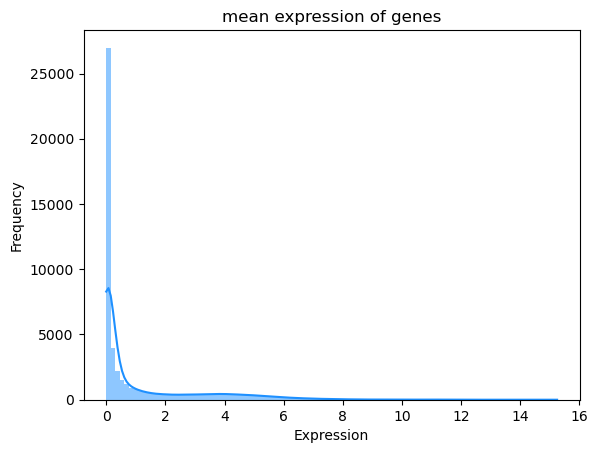

In [143]:
plot_freq(transcriptomics.mean(),
          title='mean expression of genes', bins=100)

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


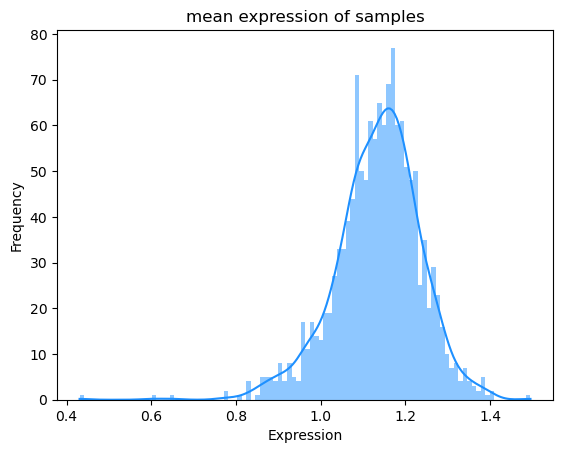

In [144]:
plot_freq(transcriptomics.T.mean(),
          title='mean expression of samples', bins=100)

In [19]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(transcriptomics.T)

pca_df = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2'])

In [20]:
umap_model = umap.UMAP(n_components=2)
umap_result = umap_model.fit_transform(transcriptomics.T)

umap_df = pd.DataFrame(data=umap_result, columns=['UMAP1', 'UMAP2'])

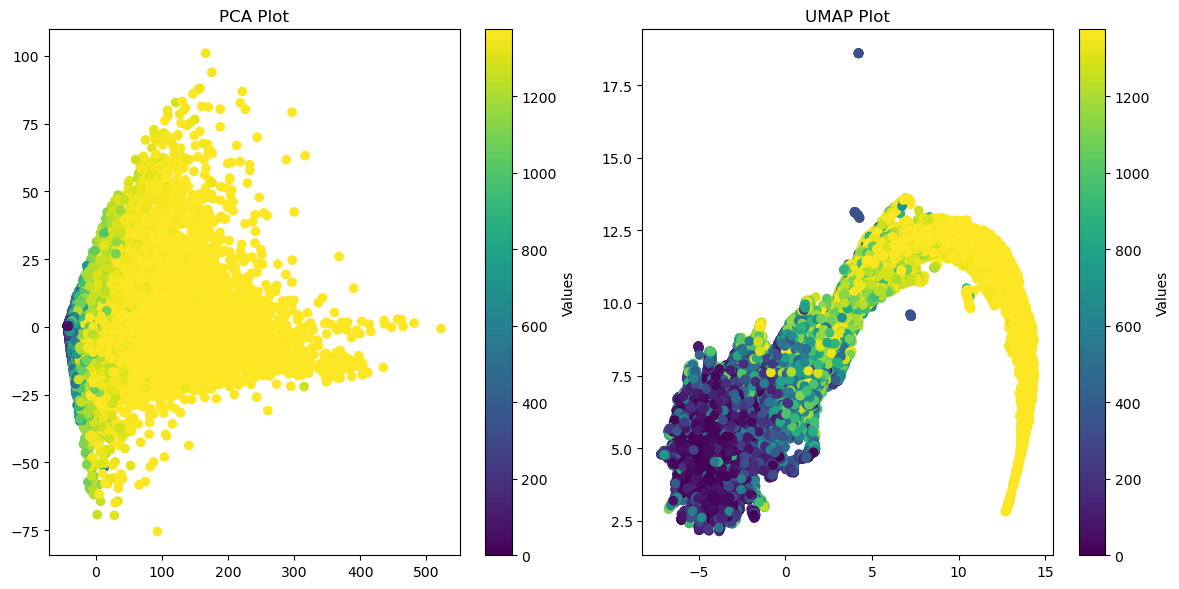

In [153]:
from matplotlib import cm
import matplotlib.colors as mcolors

values = (transcriptomics != 0).sum()

norm = mcolors.Normalize(vmin=np.min(values), vmax=np.max(values))
cmap = cm.viridis

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
scatter = plt.scatter(pca_df['PC1'], pca_df['PC2'], c=values, cmap=cmap, norm=norm)
plt.title('PCA Plot')
plt.colorbar(scatter, label='Values')

plt.subplot(1, 2, 2)
scatter = plt.scatter(umap_df['UMAP1'], umap_df['UMAP2'], c=values, cmap=cmap, norm=norm)
plt.title('UMAP Plot')
plt.colorbar(scatter, label='Values')

plt.tight_layout()
plt.show()

In [27]:
m = len(transcriptomics)
n = len(transcriptomics.T)
m, n

(1375, 51989)

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


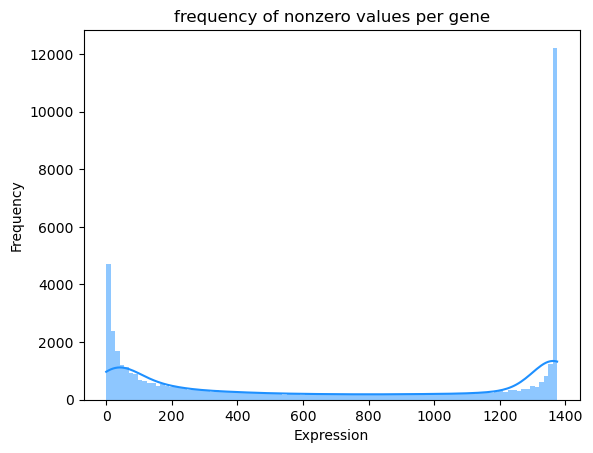

In [26]:
plot_freq((transcriptomics != 0).sum(),
          title='frequency of nonzero values per gene', bins=100)

C:\Users\ccald\AppData\Local\Temp\ipykernel_3292\1981201996.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(transcriptomics.mean(), shade=True)
c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


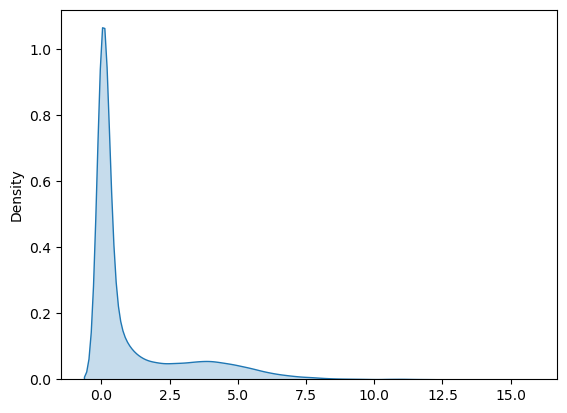

In [28]:
sns.kdeplot(transcriptomics.mean(), shade=True)
plt.show()

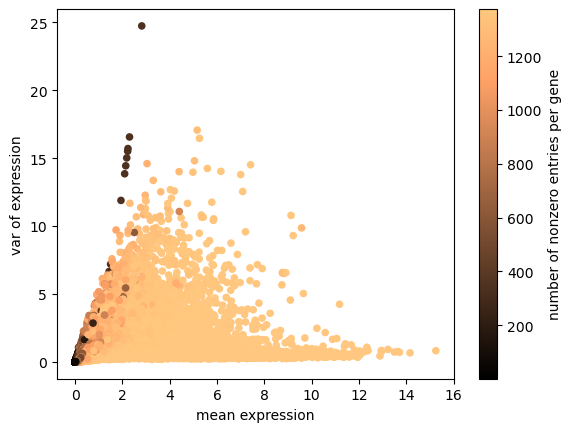

In [29]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.var()[transcriptomics.std() > t]
z = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

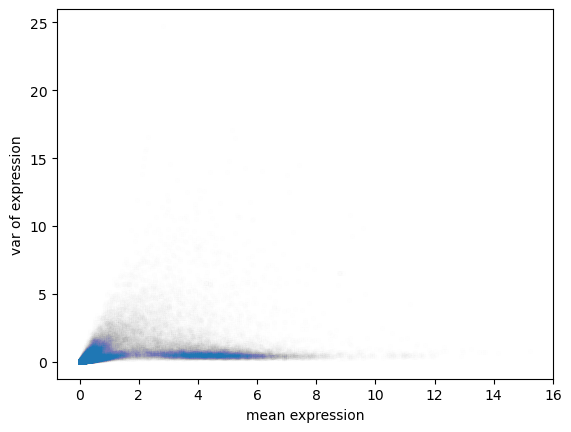

In [46]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.var()[transcriptomics.std() > t]
z = (transcriptomics != 0).sum()[transcriptomics.std() > t]
z = np.ones(len(x))

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

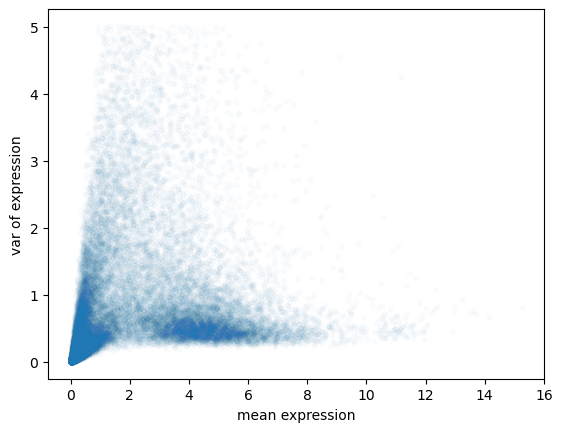

In [31]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)
u = transcriptomics.std().quantile(0.99)

x = transcriptomics.mean()[(transcriptomics.std() > t) & (transcriptomics.std() < u)]
y = transcriptomics.var()[(transcriptomics.std() > t) & (transcriptomics.std() < u)]
z = (transcriptomics != 0).sum()[(transcriptomics.std() > t) & (transcriptomics.std() < u)]
z = np.ones(len(x))

plt.scatter(x, y, s=10, alpha=0.02)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

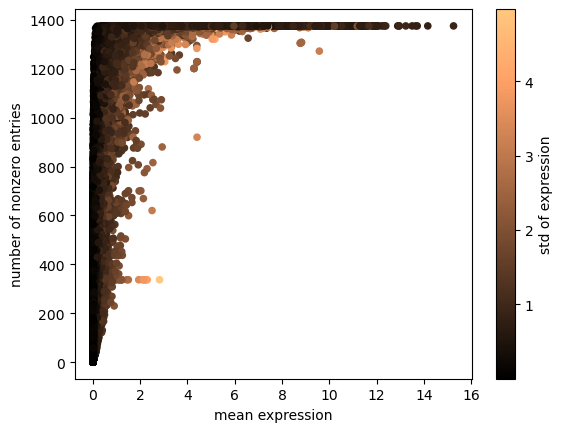

In [34]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
z = transcriptomics.std()[transcriptomics.std() > t]
y = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='std of expression')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

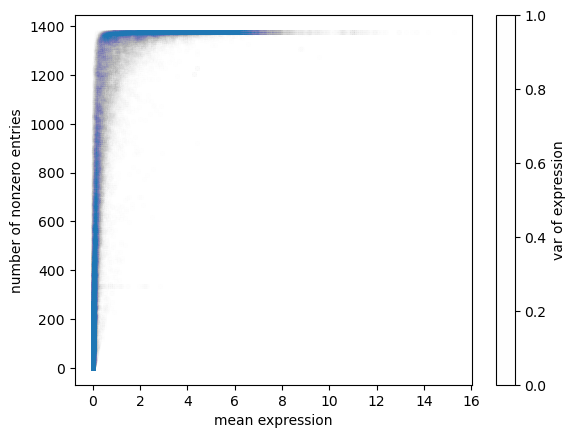

In [ ]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
z = transcriptomics.std()[transcriptomics.std() > t]
y = (transcriptomics != 0).sum()[transcriptomics.std() > t]
z = np.ones(len(x))

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

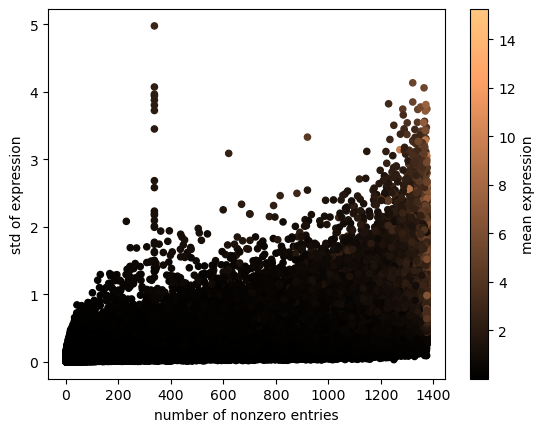

In [35]:
t = transcriptomics.std().quantile(0)

z = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.std()[transcriptomics.std() > t]
x = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='mean expression')

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

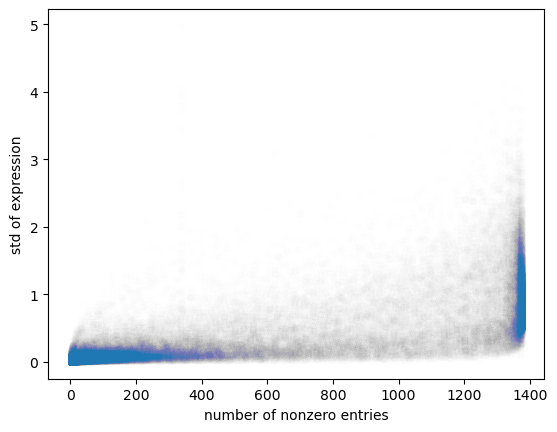

In [71]:
t = transcriptomics.std().quantile(0)

z = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.std()[transcriptomics.std() > t]
x = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, s=20, alpha=0.005)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

## Filtered plots

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


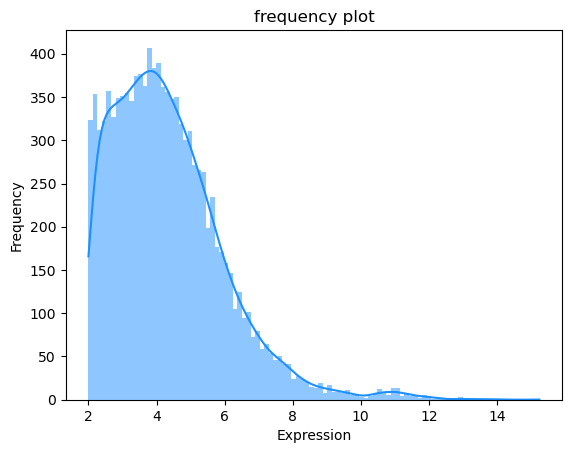

In [39]:
plot_freq(transcriptomics.mean()[transcriptomics.mean() > 2],
          title='frequency plot', bins=100)

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


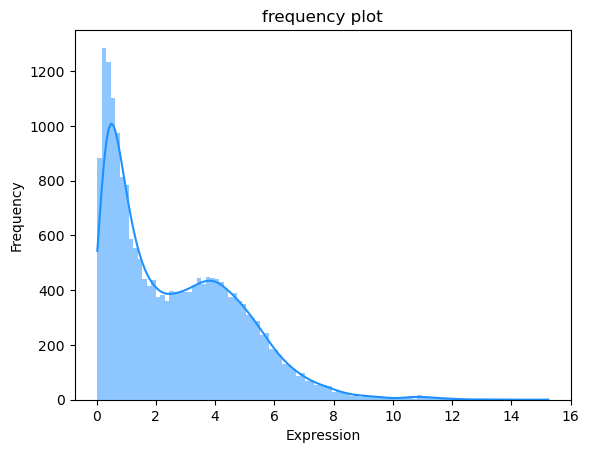

In [41]:
plot_freq(transcriptomics.mean()[(transcriptomics != 0).sum() > 1000],
          title='frequency plot', bins=100)

### Mean expression filtering

In [55]:
transcriptomics_mean_filtered = transcriptomics.T[transcriptomics.mean() > 2].T
transcriptomics_mean_filtered.shape

(1375, 11187)

In [98]:
transcriptomics_mean_filtered.shape

(1375, 11187)

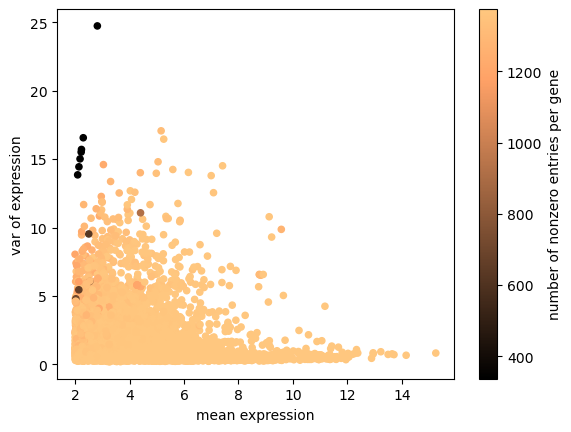

In [56]:
x = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.var()
z = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

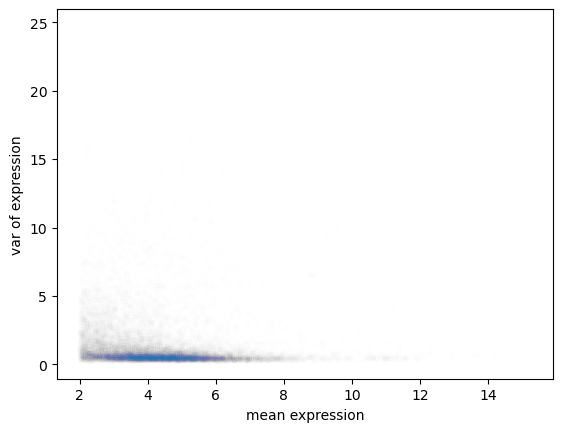

In [57]:
x = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.var()
z = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

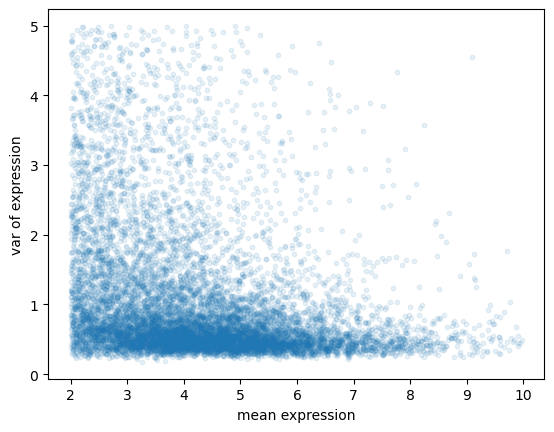

In [ ]:
# zoommed plot

x = transcriptomics_mean_filtered.mean()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
y = transcriptomics_mean_filtered.var()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
z = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]

plt.scatter(x, y, s=10, alpha=0.1)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

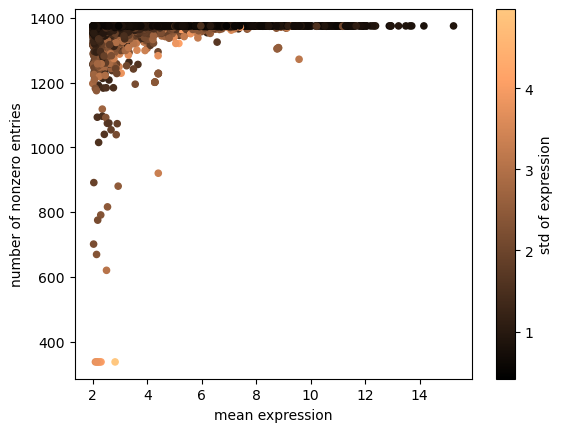

In [60]:
x = transcriptomics_mean_filtered.mean()
z = transcriptomics_mean_filtered.std()
y = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='std of expression')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

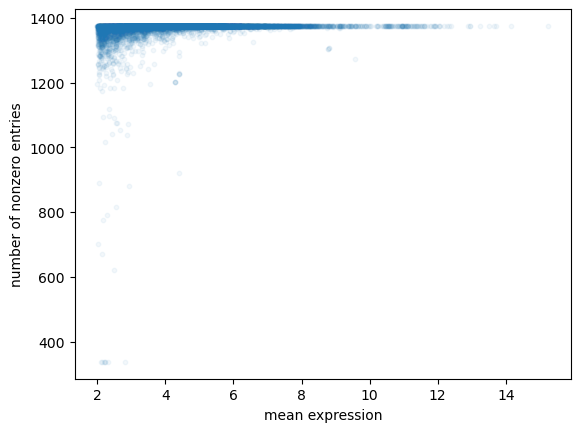

In [62]:
x = transcriptomics_mean_filtered.mean()
z = transcriptomics_mean_filtered.var()
y = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

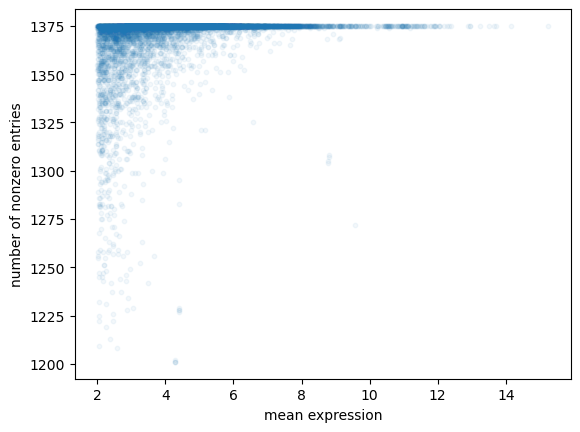

In [69]:
# zoommed

x = transcriptomics_mean_filtered.mean()[(transcriptomics_mean_filtered != 0).sum() > 1200]
z = transcriptomics_mean_filtered.var()[(transcriptomics_mean_filtered != 0).sum() > 1200]
y = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics_mean_filtered != 0).sum() > 1200]

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

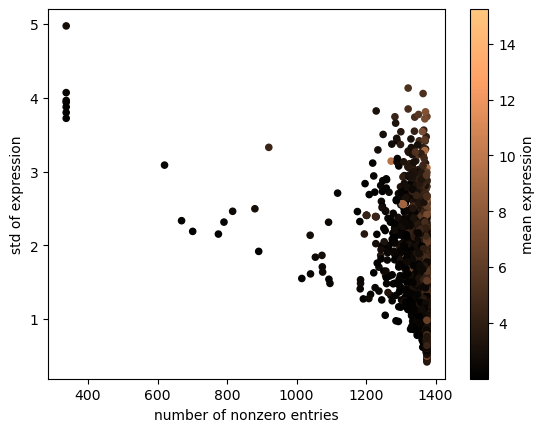

In [70]:
z = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.std()
x = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='mean expression')

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

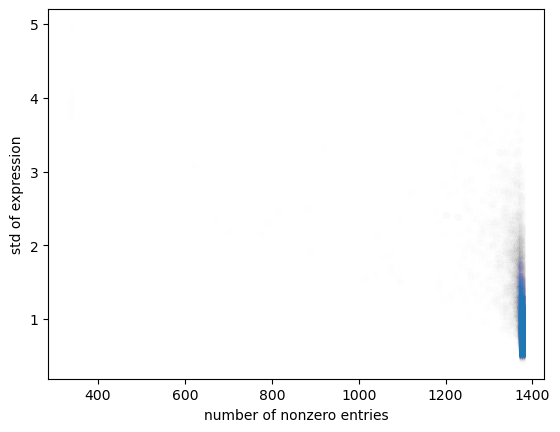

In [72]:
z = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.std()
x = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, s=20, alpha=0.005)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

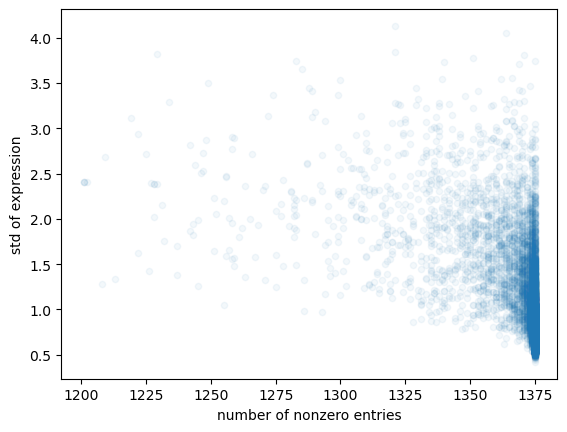

In [75]:
# zoommed

z = transcriptomics_mean_filtered.mean()[(transcriptomics_mean_filtered != 0).sum() > 1200]
y = transcriptomics_mean_filtered.std()[(transcriptomics_mean_filtered != 0).sum() > 1200]
x = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics_mean_filtered != 0).sum() > 1200]

plt.scatter(x, y, s=20, alpha=0.05)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

### Non-zeros count filtering

In [76]:
transcriptomics_nonzero_filtered = transcriptomics.T[(transcriptomics != 0).sum() > 1000].T

In [97]:
transcriptomics_nonzero_filtered.shape

(1375, 21201)

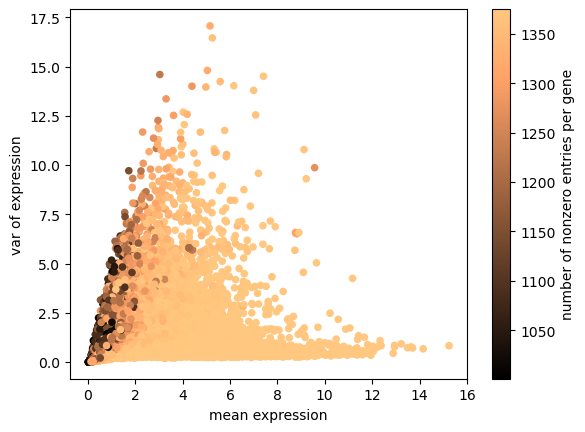

In [77]:
x = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.var()
z = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

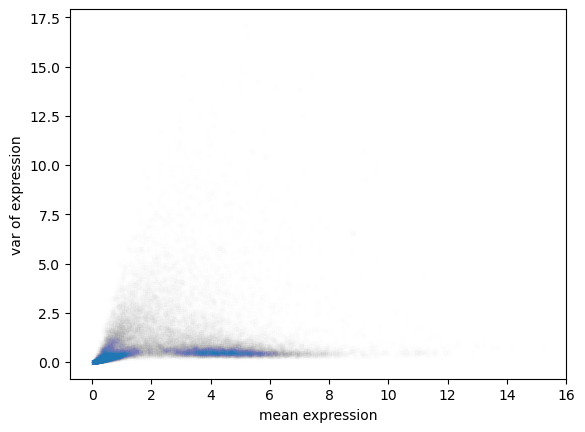

In [78]:
x = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.var()
z = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

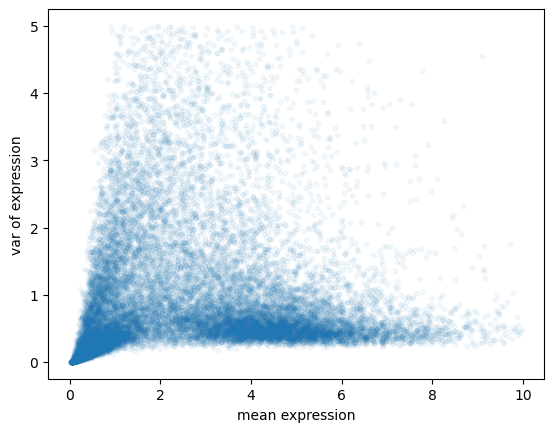

In [81]:
# zoommed plot

x = transcriptomics_nonzero_filtered.mean()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
y = transcriptomics_nonzero_filtered.var()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
z = (transcriptomics_nonzero_filtered != 0).sum()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

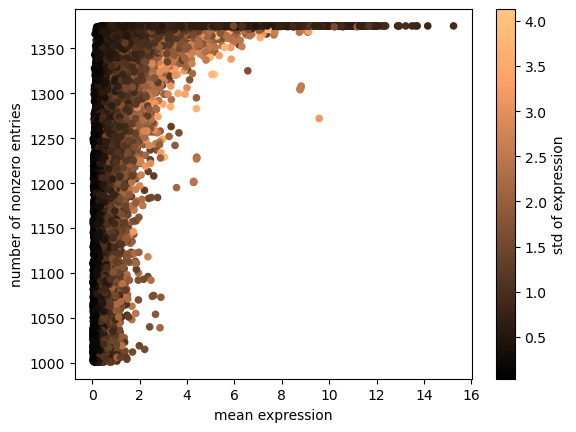

In [82]:
x = transcriptomics_nonzero_filtered.mean()
z = transcriptomics_nonzero_filtered.std()
y = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='std of expression')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

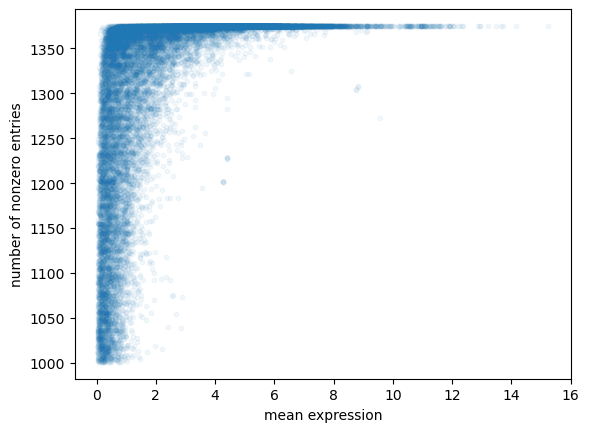

In [83]:
x = transcriptomics_nonzero_filtered.mean()
z = transcriptomics_nonzero_filtered.var()
y = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

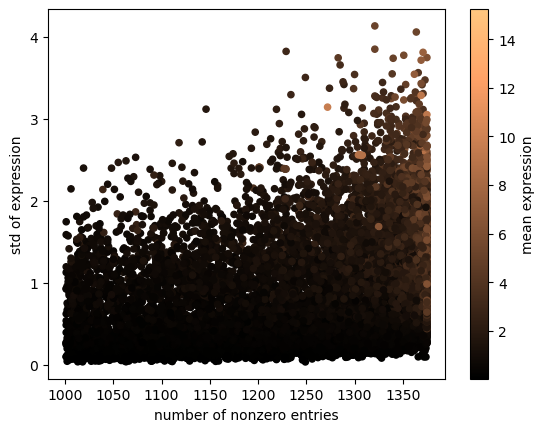

In [88]:
z = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.std()
x = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='mean expression')

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

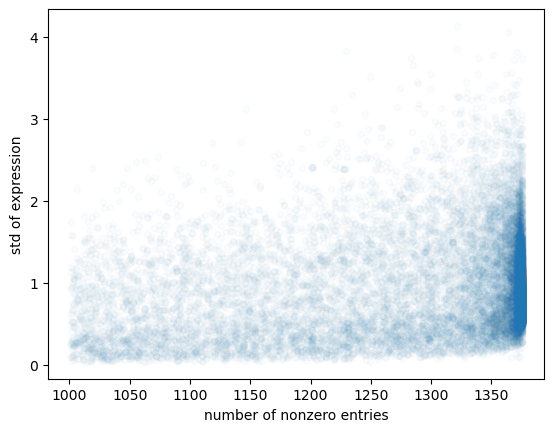

In [96]:
z = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.std()
x = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, s=20, alpha=0.02)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()